In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from initial_state import ValidationSpec, sample_validation_batch
from controllers.sindy_lqr import SINDyLQRController
from eval.rollout import rollout_controller
from eval.metrics import rollout_metrics

ARTIFACT     = ROOT / "artifacts/controllers/sindy_lqr.pkl"
VAL_SPEC     = ROOT / "artifacts/validation/sindy_lqr_val_spec.npz"
VAL_ROLLOUTS = ROOT / "artifacts/validation/sindy_lqr_stress_rollouts.npz"
VAL_METRICS  = ROOT / "artifacts/validation/sindy_lqr_stress_metrics.npz"

N_CASES     = 100
SEED        = 42
FORCE_RANGE = (0.5, 5.0)   # N
ANGLE_RANGE = (5.0, 90.0)  # degrees
T_END       = 20.0
DT          = 0.02
FORCE_LIMIT = 5.0

## 1. Validation Specification

Sample 100 cases by drawing an impulse force uniformly from \[0.5, 5\] N and a target
crossing angle uniformly from \[5, 90\] degrees.  The initial state is the system state at
the moment the pendulum first crosses that angle under the impulse.  Cases where the
impulse cannot reach the target angle are marked infeasible.

In [2]:
if VAL_SPEC.exists():
    spec = ValidationSpec.load(VAL_SPEC)
    print(f"Loaded spec from {VAL_SPEC}")
else:
    print(f"Generating {N_CASES} validation cases (seed={SEED})...")
    spec = sample_validation_batch(
        n_cases=N_CASES,
        seed=SEED,
        force_range=FORCE_RANGE,
        angle_range_deg=ANGLE_RANGE,
    )
    spec.save(VAL_SPEC)
    print(f"Saved to {VAL_SPEC}")

print(f"  total: {spec.n}  feasible: {spec.n_feasible}  "
      f"({100 * spec.n_feasible / spec.n:.0f}%)")
feas = spec.feasible
print(f"  force range (feasible):  [{spec.forces[feas].min():.2f}, "
      f"{spec.forces[feas].max():.2f}] N")
print(f"  angle range (feasible):  [{spec.angles_deg[feas].min():.1f}, "
      f"{spec.angles_deg[feas].max():.1f}] deg")

Generating 100 validation cases (seed=42)...
Saved to /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/validation/sindy_lqr_val_spec.npz
  total: 100  feasible: 100  (100%)
  force range (feasible):  [0.53, 4.89] N
  angle range (feasible):  [6.8, 89.4] deg


## 2. Baseline SINDy-LQR Controller

Load the pre-trained controller from the artifact written by `05_sindy_lqr.ipynb`.

In [3]:
if not ARTIFACT.exists():
    raise FileNotFoundError(
        f"No baseline controller at {ARTIFACT}.\n"
        "Run notebooks/05_sindy_lqr.ipynb first."
    )
controller = SINDyLQRController.load(ARTIFACT)
print(f"Loaded baseline controller")
print(f"  alpha={controller.metadata.get('alpha')}  "
      f"force_limit={controller.force_limit} N")
print("  Learned equations:")
for eq in controller.metadata["model"]["equations"]:
    print(f"    {eq}")

Loaded baseline controller
  alpha=0.75  force_limit=5.0 N
  Learned equations:
    x_next = 1*x + 0.01003*x_dot
    x_dot_next = 0.9999*x_dot + 0.007078*u + -0.02327*sin(theta)
    theta_next = 1*theta + 0.01002*theta_dot
    theta_dot_next = 0.9998*theta_dot + 0.2135*sin(theta) + 0.01827*u*cos(theta)


## 3. Run 100 Rollouts

Evaluate the baseline controller from each feasible initial condition.
Results are cached to `artifacts/validation/` so this cell is a no-op on reruns.

In [4]:
n_steps = int(round(T_END / DT)) + 1

if VAL_ROLLOUTS.exists():
    _d = np.load(VAL_ROLLOUTS)
    states_arr    = _d["states"]            # (N, 4, n_steps)
    inputs_arr    = _d["inputs"]            # (N, n_steps)
    t_arr         = _d["t"]                 # (n_steps,)
    rollout_ok    = _d["success"].astype(bool)  # (N,)
    print(f"Loaded rollouts from {VAL_ROLLOUTS}")
else:
    states_arr = np.full((spec.n, 4, n_steps), np.nan)
    inputs_arr = np.full((spec.n, n_steps), np.nan)
    t_arr      = None
    rollout_ok = np.zeros(spec.n, dtype=bool)

    for i in range(spec.n):
        if not spec.feasible[i]:
            continue
        result = rollout_controller(
            controller, spec.initial_states[i],
            t_end=T_END, dt=DT, force_limit=FORCE_LIMIT,
        )
        if t_arr is None:
            t_arr = result.t
        states_arr[i] = result.y
        inputs_arr[i] = result.u
        rollout_ok[i] = result.success
        if (i + 1) % 10 == 0:
            print(f"  {i + 1}/{spec.n} complete")

    if t_arr is None:
        t_arr = np.arange(0.0, T_END + 0.5 * DT, DT)

    VAL_ROLLOUTS.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        VAL_ROLLOUTS,
        states=states_arr, inputs=inputs_arr,
        t=t_arr, success=rollout_ok,
    )
    print(f"Saved rollouts to {VAL_ROLLOUTS}")

print(f"  rollout_ok: {rollout_ok.sum()} / {spec.feasible.sum()} feasible cases")

  10/100 complete
  20/100 complete
  30/100 complete
  40/100 complete
  50/100 complete
  60/100 complete
  70/100 complete
  80/100 complete
  90/100 complete
  100/100 complete
Saved rollouts to /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/validation/sindy_lqr_stress_rollouts.npz
  rollout_ok: 100 / 100 feasible cases


## 4. Metrics Summary

In [5]:
records = []
for i in range(spec.n):
    row = {
        "case": i,
        "force_N":   float(spec.forces[i]),
        "angle_deg": float(spec.angles_deg[i]),
        "feasible":  bool(spec.feasible[i]),
    }
    if spec.feasible[i] and rollout_ok[i]:
        m = rollout_metrics(t_arr, states_arr[i], inputs_arr[i])
        row.update(m)
    records.append(row)

feas_records = [r for r in records if r["feasible"] and "success" in r]
n_feas = len(feas_records)
n_succ = sum(1 for r in feas_records if r.get("success"))
n_nofall = sum(1 for r in feas_records if r.get("no_fall"))

costs  = [r["cost"]   for r in feas_records if "cost"   in r]
st     = [r["settle_and_remain_time"] for r in feas_records
          if r.get("settle_and_remain_time") is not None]
energy = [r["control_energy"] for r in feas_records if "control_energy" in r]

print("=" * 50)
print("SINDy-LQR Stress Test — 100 Random Initial Conditions")
print("=" * 50)
print(f"  Total cases:      {spec.n}")
print(f"  Feasible:         {n_feas}")
print(f"  Success rate:     {n_succ}/{n_feas}  "
      f"({100 * n_succ / max(1, n_feas):.1f}%)")
print(f"  No-fall rate:     {n_nofall}/{n_feas}  "
      f"({100 * n_nofall / max(1, n_feas):.1f}%)")
if costs:
    print(f"  Cost:             median={np.median(costs):.1f}  "
          f"mean={np.mean(costs):.1f}  max={np.max(costs):.1f}")
if st:
    print(f"  Settle time (s):  median={np.median(st):.2f}  "
          f"mean={np.mean(st):.2f}  max={np.max(st):.2f}")
if energy:
    print(f"  Control energy:   median={np.median(energy):.2f}  "
          f"mean={np.mean(energy):.2f}")
print()
# Per-case table (first 20 sorted by angle)
sorted_recs = sorted(feas_records, key=lambda r: r["angle_deg"])
print(f"{'case':>4}  {'angle':>7}  {'force':>6}  {'success':>7}  "
      f"{'settle_t':>9}  {'cost':>8}")
print("-" * 57)
for r in sorted_recs[:20]:
    st_str = f"{r['settle_and_remain_time']:.2f}" \
             if r.get('settle_and_remain_time') is not None else "   None"
    print(f"{r['case']:>4}  {r['angle_deg']:>6.1f}°  {r['force_N']:>5.2f}N  "
          f"{str(r.get('success')):>7}  {st_str:>9}  "
          f"{r.get('cost', float('nan')):>8.1f}")
if len(sorted_recs) > 20:
    print(f"  ... ({len(sorted_recs) - 20} more rows)")

SINDy-LQR Stress Test — 100 Random Initial Conditions
  Total cases:      100
  Feasible:         100
  Success rate:     5/100  (5.0%)
  No-fall rate:     5/100  (5.0%)
  Cost:             median=129706483.7  mean=118641502.4  max=148292084.0
  Settle time (s):  median=3.02  mean=2.91  max=3.24
  Control energy:   median=500.50  mean=475.95

case    angle   force  success   settle_t      cost
---------------------------------------------------------
  49     6.8°   1.13N     True       2.56      34.9
  35     6.9°   1.35N     True       2.60      36.6
  63     8.2°   3.94N     True       3.02      64.9
  24     8.5°   4.00N     True       3.14      76.8
  75     8.8°   1.77N     True       3.24      88.1
  39    12.0°   3.51N    False       None  66488037.3
  22    12.2°   4.87N    False       None  68440553.6
  87    13.0°   2.58N    False       None  75311779.8
   8    13.2°   1.08N    False       None  76268330.0
  28    13.8°   1.19N    False       None  79123094.3
  60    14.2°  

## 5. Performance Breakdown Plots

Success rate bucketed by target angle and by impulse force, plus a scatter
plot showing every case coloured by outcome.

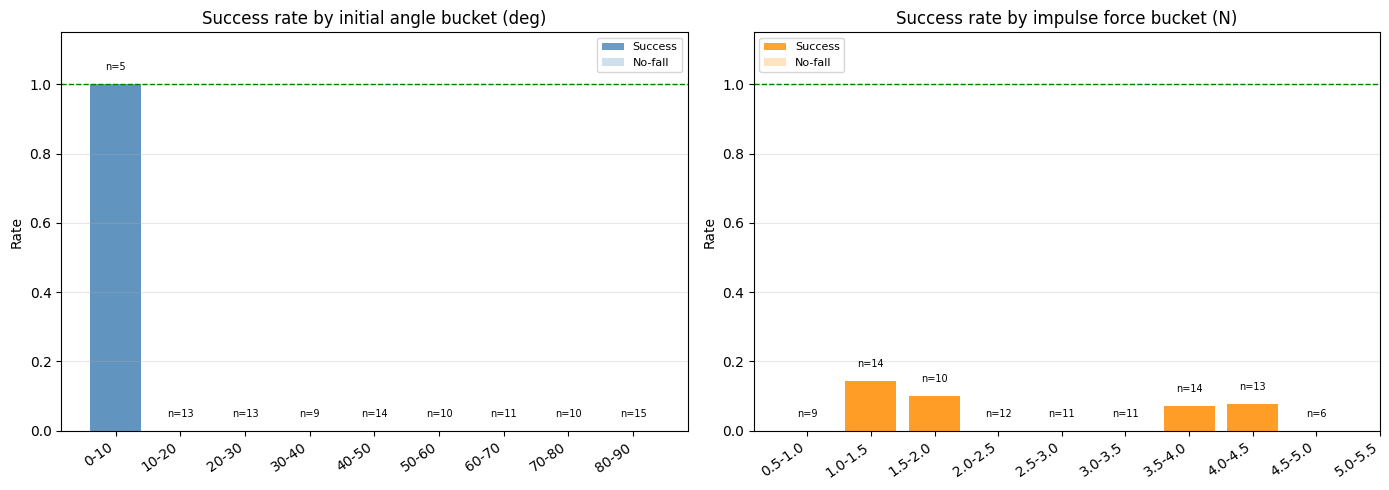

In [6]:
def _bucket_rates(records, key, bins):
    """Compute per-bin success rate, no-fall rate, and count."""
    success_rates, nofall_rates, counts = [], [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        bucket = [r for r in records if lo <= r[key] < hi]
        n = len(bucket)
        counts.append(n)
        if n > 0:
            success_rates.append(sum(1 for r in bucket if r.get("success")) / n)
            nofall_rates.append(sum(1 for r in bucket if r.get("no_fall")) / n)
        else:
            success_rates.append(np.nan)
            nofall_rates.append(np.nan)
    return success_rates, nofall_rates, counts


angle_bins = np.arange(0, 100, 10)
force_bins = np.arange(0.5, 5.6, 0.5)

a_succ, a_nf, a_cnt = _bucket_rates(feas_records, "angle_deg", angle_bins)
f_succ, f_nf, f_cnt = _bucket_rates(feas_records, "force_N",   force_bins)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Angle bucket ---
ax = axes[0]
x_pos = np.arange(len(angle_bins) - 1)
labels = [f"{int(b)}-{int(b+10)}" for b in angle_bins[:-1]]
bars = ax.bar(x_pos, a_succ, color="steelblue", alpha=0.8, label="Success")
ax.bar(x_pos, a_nf, color="steelblue", alpha=0.25, label="No-fall",
       bottom=0, linewidth=0)
ax.set_xticks(x_pos)
ax.set_xticklabels(labels, rotation=35, ha="right")
ax.set_ylabel("Rate")
ax.set_title("Success rate by initial angle bucket (deg)")
ax.set_ylim(0, 1.15)
ax.axhline(1.0, color="green", linestyle="--", linewidth=1)
ax.legend(fontsize=8)
for bar, n in zip(bars, a_cnt):
    if n > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            (bar.get_height() or 0) + 0.04,
            f"n={n}", ha="center", fontsize=7,
        )
ax.grid(axis="y", alpha=0.3)

# --- Force bucket ---
ax2 = axes[1]
x_pos2 = np.arange(len(force_bins) - 1)
labels2 = [f"{b:.1f}-{b+0.5:.1f}" for b in force_bins[:-1]]
bars2 = ax2.bar(x_pos2, f_succ, color="darkorange", alpha=0.8, label="Success")
ax2.bar(x_pos2, f_nf, color="darkorange", alpha=0.25, label="No-fall",
        bottom=0, linewidth=0)
ax2.set_xticks(x_pos2)
ax2.set_xticklabels(labels2, rotation=35, ha="right")
ax2.set_ylabel("Rate")
ax2.set_title("Success rate by impulse force bucket (N)")
ax2.set_ylim(0, 1.15)
ax2.axhline(1.0, color="green", linestyle="--", linewidth=1)
ax2.legend(fontsize=8)
for bar, n in zip(bars2, f_cnt):
    if n > 0:
        ax2.text(
            bar.get_x() + bar.get_width() / 2,
            (bar.get_height() or 0) + 0.04,
            f"n={n}", ha="center", fontsize=7,
        )
ax2.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

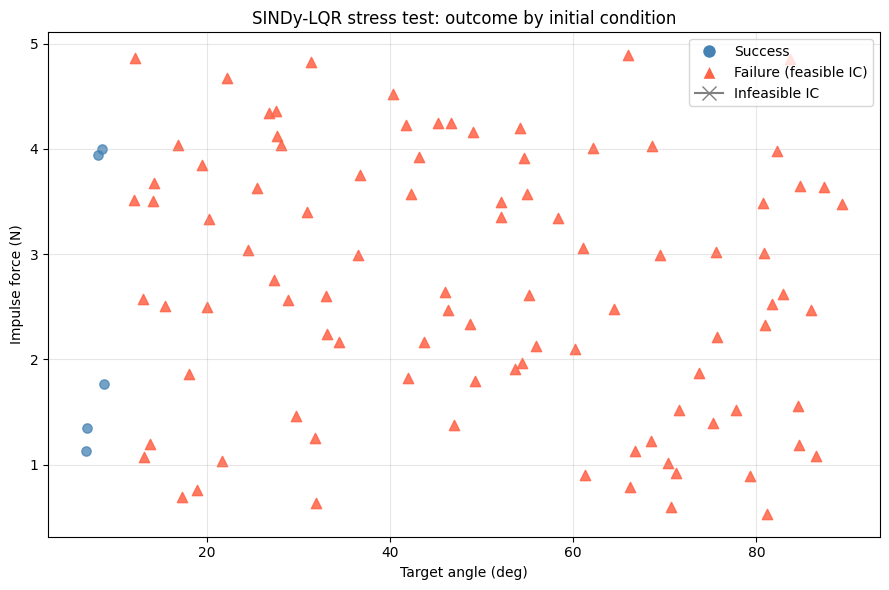

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))
for r in records:
    if not r["feasible"]:
        ax.scatter(r["angle_deg"], r["force_N"],
                   marker="x", color="gray", s=40, linewidths=1.2)
    elif r.get("success"):
        ax.scatter(r["angle_deg"], r["force_N"],
                   marker="o", color="steelblue", s=45, alpha=0.75)
    else:
        ax.scatter(r["angle_deg"], r["force_N"],
                   marker="^", color="tomato", s=55, alpha=0.85)

legend_elements = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor="steelblue",
           markersize=10, label="Success"),
    Line2D([0], [0], marker="^", color="w", markerfacecolor="tomato",
           markersize=10, label="Failure (feasible IC)"),
    Line2D([0], [0], marker="x", color="gray",
           markersize=10, label="Infeasible IC"),
]
ax.legend(handles=legend_elements, loc="upper right")
ax.set_xlabel("Target angle (deg)")
ax.set_ylabel("Impulse force (N)")
ax.set_title("SINDy-LQR stress test: outcome by initial condition")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Save Artifacts

Per-case metrics are saved to `artifacts/validation/sindy_lqr_stress_metrics.npz`
for consumption by `05b_sindy_lqr_crossval.ipynb`.

In [8]:
def _to_float(v):
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return np.nan
    try:
        return float(v)
    except (TypeError, ValueError):
        return np.nan

def _to_bool_float(v):
    return float(v) if isinstance(v, (bool, np.bool_)) else np.nan


metrics_to_save = {
    "force_N":             spec.forces,
    "angle_deg":           spec.angles_deg,
    "feasible":            spec.feasible.astype(float),
    "success":             np.array([_to_bool_float(r.get("success"))       for r in records]),
    "no_fall":             np.array([_to_bool_float(r.get("no_fall"))        for r in records]),
    "settle_and_remain_time": np.array(
        [_to_float(r.get("settle_and_remain_time")) for r in records]
    ),
    "cost":                np.array([_to_float(r.get("cost"))                for r in records]),
    "max_abs_theta":       np.array([_to_float(r.get("max_abs_theta"))       for r in records]),
    "control_energy":      np.array([_to_float(r.get("control_energy"))      for r in records]),
    "mean_abs_force":      np.array([_to_float(r.get("mean_abs_force"))      for r in records]),
    "settled_fraction":    np.array([_to_float(r.get("settled_fraction"))    for r in records]),
}

VAL_METRICS.parent.mkdir(parents=True, exist_ok=True)
np.savez_compressed(VAL_METRICS, **metrics_to_save)
print(f"Saved metrics to {VAL_METRICS}")
print(f"  keys: {list(metrics_to_save.keys())}")

Saved metrics to /Users/royphillips/Documents/Rice/Grad_Research/code/inverted_pendulum/artifacts/validation/sindy_lqr_stress_metrics.npz
  keys: ['force_N', 'angle_deg', 'feasible', 'success', 'no_fall', 'settle_and_remain_time', 'cost', 'max_abs_theta', 'control_energy', 'mean_abs_force', 'settled_fraction']
